# Data Privacy and Protection, PII Anonymization

In [ ]:
# Install required packages:
# !pip install langchain langchain-experimental openai presidio-analyzer presidio-anonymizer spacy Faker faiss-cpu tiktoken
# !python -m spacy download en_core_web_lg

In [1]:
# Load environment variables:
from dotenv import load_dotenv

load_dotenv()

True

## Iterative process of upgrading the anonymizer

This is our text filled with synthetic PII values.

In [39]:
document_content = """Date: October 19, 2021
Witness: John Doe
Subject: Testimony Regarding the loss of Wallet

Testimony Content:

Hello, Officer

My name is John Doe and on October 19, 2021, my wallet was stolen in the vicinity of Kilmarnock during a bike trip. 
This wallet contains some very important things to me.

Firstly, the wallet contains my credit card with number 4111 1111 1111 1111, which is registered under my name and
linked to my bank account, PL61109010140000071219812874.

Additionally, the wallet had my driver's license - DL No: 999000680 issued to my name. It also houses my Social Security Number, 
602-76-4532.

What's more, I had my Polish identity card there, with the number ABC123456.

I would like this data to be secured and protected in all possible ways. I believe it was stolen at 9:30 AM.

In case any information arises regarding my wallet, please reach out to me on my phone number, 999-888-7777, or through my personal email, 
johndoe@example.com.

Please consider this information to be highly confidential and respect my privacy.

The banks have been informed about the stolen credit card and necessary actions have been taken from their end. They will be reachable at 
their official email, support@bankname.com.
My representative there is Victoria Cherry (her business phone: 987-654-3210).

Thank you for your assistance,

John Doe"""

In [40]:
document_content

"Date: October 19, 2021\nWitness: John Doe\nSubject: Testimony Regarding the loss of Wallet\n\nTestimony Content:\n\nHello, Officer\n\nMy name is John Doe and on October 19, 2021, my wallet was stolen in the vicinity of Kilmarnock during a bike trip. \nThis wallet contains some very important things to me.\n\nFirstly, the wallet contains my credit card with number 4111 1111 1111 1111, which is registered under my name and\nlinked to my bank account, PL61109010140000071219812874.\n\nAdditionally, the wallet had my driver's license - DL No: 999000680 issued to my name. It also houses my Social Security Number, \n602-76-4532.\n\nWhat's more, I had my Polish identity card there, with the number ABC123456.\n\nI would like this data to be secured and protected in all possible ways. I believe it was stolen at 9:30 AM.\n\nIn case any information arises regarding my wallet, please reach out to me on my phone number, 999-888-7777, or through my personal email, \njohndoe@example.com.\n\nPlease co

In [41]:
from langchain.schema import Document

documents = [Document(page_content=document_content)]

We only have one document.

The text contains many PII values, some occur many times (e.g. names, phone number, emails) and some are repeated.

In [42]:
# Util function for coloring the PII markers
# Note: It will not be visible on documentation page, only in the notebook.

import re

def print_colored_pii(string: str):
    colored_string = re.sub(
        r"(<[^>]*>)", lambda m: "\033[31m" + m.group(1) + "\033[0m", string
    )
    print(colored_string)


Trying to anonymize the text with default settings.

For now, we're not replacing the data with synthetic(fake) data, we just mark it with markers (e.g. `<PERSON>`), 
so we set `add_default_faker_operators=False`:

In [43]:
from langchain_experimental.data_anonymizer import PresidioReversibleAnonymizer

anonymizer = PresidioReversibleAnonymizer(add_default_faker_operators=False)

print_colored_pii(anonymizer.anonymize(document_content))

Date: <DATE_TIME>
Witness: <PERSON>
Subject: Testimony Regarding the loss of Wallet

Testimony Content:

Hello, Officer

My name is <PERSON> and on <DATE_TIME>, my wallet was stolen in the vicinity of <LOCATION> during a bike trip. 
This wallet contains some very important things to me.

Firstly, the wallet contains my credit card with number <CREDIT_CARD>, which is registered under my name and
linked to my bank account, <IBAN_CODE>.

Additionally, the wallet had my driver's license - DL No: <US_DRIVER_LICENSE> issued to my name. It also houses my Social Security Number, 
<US_SSN>.

What's more, I had my <NRP> identity card there, with the number ABC123456.

I would like this data to be secured and protected in all possible ways. I believe it was stolen at <DATE_TIME_2>.

In case any information arises regarding my wallet, please reach out to me on my phone number, <PHONE_NUMBER>, or through my personal email, 
<EMAIL_ADDRESS>.

Please consider this information to be highly confidentia

Visit Microsoft Presidio to see the list of supported entities and their definitions. [List of supported entities](https://microsoft.github.io/presidio/supported_entities/#list-of-supported-entities).

Let's look at the mapping between the original and anonymized values.

In [44]:
import pprint

pprint.pprint(anonymizer.anonymizer_mapping)

{'CREDIT_CARD': {'4111 1111 1111 1111': '<CREDIT_CARD>'},
 'DATE_TIME': {'9:30 AM': '<DATE_TIME_2>', 'October 19, 2021': '<DATE_TIME>'},
 'EMAIL_ADDRESS': {'johndoe@example.com': '<EMAIL_ADDRESS>',
                   'support@bankname.com': '<EMAIL_ADDRESS_2>'},
 'IBAN_CODE': {'PL61109010140000071219812874': '<IBAN_CODE>'},
 'LOCATION': {'Kilmarnock': '<LOCATION>'},
 'NRP': {'Polish': '<NRP>'},
 'PERSON': {'John Doe': '<PERSON>', 'Victoria Cherry': '<PERSON_2>'},
 'PHONE_NUMBER': {'999-888-7777': '<PHONE_NUMBER>'},
 'UK_NHS': {'987-654-3210': '<UK_NHS>'},
 'US_DRIVER_LICENSE': {'999000680': '<US_DRIVER_LICENSE>'},
 'US_SSN': {'602-76-4532': '<US_SSN>'}}


1. The Datetime recognizer recognized two different entities as `DATE_TIME`, but they contain different information.
One is a date `October 19, 2021` and the other is time `9:30 AM`.

2. The Polish ID has a unique pattern, which is not by default part of the anonymizer recognizers. The value `ABC123456` is not anonymized.

The solution is to add new recognizers to the anonymizer. Read more about in the [Presidio documention](https://microsoft.github.io/presidio/analyzer/adding_recognizers/).

In [45]:
# Define the regex pattern in a Presidio `Pattern` object:
from presidio_analyzer import Pattern, PatternRecognizer

# Define the Polish ID and Time patterns:
polish_id_pattern = Pattern(
    name="polish_id_pattern",
    regex="[A-Z]{3}\\d{6}",
    score=1,
)
time_pattern = Pattern(
    name="time_pattern",
    regex="(1[0-2]|0?[1-9]):[0-5][0-9] (AM|PM)",
    score=1,
)

# Define the recognizers with one or more patterns:
polish_id_recognizer = PatternRecognizer(
    supported_entity="POLISH_ID", patterns=[polish_id_pattern]
)
time_recognizer = PatternRecognizer(
    supported_entity="TIME", patterns=[time_pattern]
)

Now, let's add the new recognizers to our anonymizer:

In [46]:
anonymizer.add_recognizer(polish_id_recognizer)
anonymizer.add_recognizer(time_recognizer)

Note that our anonymization instance remembers previously detected and anonymized values,
including those that were not detected correctly (e.g. "9:30 AM" taken as `DATE_TIME`).
So we should remove those values, or reset the entire mapping now that our recognizers have been updated:

In [47]:
anonymizer.reset_deanonymizer_mapping()

Let's look at the reset empty mapping:

In [48]:
pprint.pprint(anonymizer.anonymizer_mapping)

{}


Let's anonymize the text and see the results:

In [49]:
print_colored_pii(anonymizer.anonymize(document_content))

Date: <DATE_TIME>
Witness: <PERSON>
Subject: Testimony Regarding the loss of Wallet

Testimony Content:

Hello, Officer

My name is <PERSON> and on <DATE_TIME>, my wallet was stolen in the vicinity of <LOCATION> during a bike trip. 
This wallet contains some very important things to me.

Firstly, the wallet contains my credit card with number <CREDIT_CARD>, which is registered under my name and
linked to my bank account, <IBAN_CODE>.

Additionally, the wallet had my driver's license - DL No: <US_DRIVER_LICENSE> issued to my name. It also houses my Social Security Number, 
<US_SSN>.

What's more, I had my <NRP> identity card there, with the number <POLISH_ID>.

I would like this data to be secured and protected in all possible ways. I believe it was stolen at <TIME>.

In case any information arises regarding my wallet, please reach out to me on my phone number, <PHONE_NUMBER>, or through my personal email, 
<EMAIL_ADDRESS>.

Please consider this information to be highly confidential and

Let's look at the mapping:

In [50]:
pprint.pprint(anonymizer.anonymizer_mapping)

{'CREDIT_CARD': {'4111 1111 1111 1111': '<CREDIT_CARD>'},
 'DATE_TIME': {'October 19, 2021': '<DATE_TIME>'},
 'EMAIL_ADDRESS': {'johndoe@example.com': '<EMAIL_ADDRESS>',
                   'support@bankname.com': '<EMAIL_ADDRESS_2>'},
 'IBAN_CODE': {'PL61109010140000071219812874': '<IBAN_CODE>'},
 'LOCATION': {'Kilmarnock': '<LOCATION>'},
 'NRP': {'Polish': '<NRP>'},
 'PERSON': {'John Doe': '<PERSON>', 'Victoria Cherry': '<PERSON_2>'},
 'PHONE_NUMBER': {'999-888-7777': '<PHONE_NUMBER>'},
 'POLISH_ID': {'ABC123456': '<POLISH_ID>'},
 'TIME': {'9:30 AM': '<TIME>'},
 'UK_NHS': {'987-654-3210': '<UK_NHS>'},
 'US_DRIVER_LICENSE': {'999000680': '<US_DRIVER_LICENSE>'},
 'US_SSN': {'602-76-4532': '<US_SSN>'}}


The anonymizer has replaced the time and Polish ID entities with the `<TIME>` and `<POLISH_ID>` markers, 
and the mapping has been updated accordingly.


Now, we can proceed to the next step, which is replacing the original values with synthetic data.
To achieve this, we need to set `add_default_faker_operators=True` (or remove this parameters, because it's set to `True` by default):

In [51]:
anonymizer = PresidioReversibleAnonymizer(
    add_default_faker_operators=True, 
    # Faker seed is used here to ensure the same fake data is generated for test purposes.
    # In production, it's recommended to remove the faker_seed parameter (it will default to None)
    faker_seed=42,
)

anonymizer.add_recognizer(polish_id_recognizer)
anonymizer.add_recognizer(time_recognizer)

print_colored_pii(anonymizer.anonymize(document_content))

Date: 1990-12-05
Witness: Brian Cox DVM
Subject: Testimony Regarding the loss of Wallet

Testimony Content:

Hello, Officer

My name is Brian Cox DVM and on 1990-12-05, my wallet was stolen in the vicinity of New Rita during a bike trip. 
This wallet contains some very important things to me.

Firstly, the wallet contains my credit card with number 6584801845146275, which is registered under my name and
linked to my bank account, GB78GSWK37672423884969.

Additionally, the wallet had my driver's license - DL No: 781802744 issued to my name. It also houses my Social Security Number, 
719-88-1170.

What's more, I had my 57683626 identity card there, with the number <POLISH_ID>.

I would like this data to be secured and protected in all possible ways. I believe it was stolen at <TIME>.

In case any information arises regarding my wallet, please reach out to me on my phone number, 7344131647, or through my personal email, 
jamesmichael@example.com.

Please consider this information to be hi

All the values have been replaced with synthetic ones, except the Polish ID and time, which are not supported by default faker operators.

We can add new operators to the anonymizer, which will generate random data.

In [52]:
from faker import Faker

fake = Faker()

def fake_polish_id(_ = None):
    return fake.bothify(text="???######").upper()

fake_polish_id()

'CHT738620'

In [53]:
def fake_time(_ = None):
    return fake.time(pattern="%I:%M %p")

fake_time()

'01:54 AM'

Let's add the new operators to the anonymizer:

In [54]:
from presidio_anonymizer.entities import OperatorConfig

new_operators = {
    "POLISH_ID": OperatorConfig("custom", { "lambda": fake_polish_id }),
    "TIME": OperatorConfig("custom", { "lambda": fake_time }),
}

anonymizer.add_operators(new_operators)

Now we'll anonymize everything once again:

In [55]:
anonymizer.reset_deanonymizer_mapping()
print_colored_pii(anonymizer.anonymize(document_content))

Date: 1974-12-26
Witness: Jimmy Murillo
Subject: Testimony Regarding the loss of Wallet

Testimony Content:

Hello, Officer

My name is Jimmy Murillo and on 1974-12-26, my wallet was stolen in the vicinity of South Dianeshire during a bike trip. 
This wallet contains some very important things to me.

Firstly, the wallet contains my credit card with number 213108121913614, which is registered under my name and
linked to my bank account, GB96CYHF67736026064746.

Additionally, the wallet had my driver's license - DL No: 217326729 issued to my name. It also houses my Social Security Number, 
413-94-5560.

What's more, I had my 97705310 identity card there, with the number OQK707900.

I would like this data to be secured and protected in all possible ways. I believe it was stolen at 05:04 PM.

In case any information arises regarding my wallet, please reach out to me on my phone number, 876.931.1656, or through my personal email, 
briannasmith@example.net.

Please consider this information

In [56]:
pprint.pprint(anonymizer.deanonymizer_mapping)

{'CREDIT_CARD': {'213108121913614': '4111 1111 1111 1111'},
 'DATE_TIME': {'1974-12-26': 'October 19, 2021'},
 'EMAIL_ADDRESS': {'briannasmith@example.net': 'johndoe@example.com',
                   'samuel87@example.org': 'support@bankname.com'},
 'IBAN_CODE': {'GB96CYHF67736026064746': 'PL61109010140000071219812874'},
 'LOCATION': {'South Dianeshire': 'Kilmarnock'},
 'NRP': {'97705310': 'Polish'},
 'PERSON': {'Jimmy Murillo': 'John Doe', 'Tracey Hickman': 'Victoria Cherry'},
 'PHONE_NUMBER': {'876.931.1656': '999-888-7777'},
 'POLISH_ID': {'OQK707900': 'ABC123456'},
 'TIME': {'05:04 PM': '9:30 AM'},
 'UK_NHS': {'8128575500': '987-654-3210'},
 'US_DRIVER_LICENSE': {'217326729': '999000680'},
 'US_SSN': {'413-94-5560': '602-76-4532'}}


Now all the values are replaced with sythentic data. Note that the deanonymizer mapping has been updated accordingly.

## Question-answering with PII anonymization

To bring it all together, we'll create a QA system, based on `PresidioReversibleAnonymizer` and LangChain Expression Language (LCEL).

In [57]:
# 1. Initialize anonymizer
anonymizer = PresidioReversibleAnonymizer(
    faker_seed=42
)

anonymizer.add_recognizer(polish_id_recognizer)
anonymizer.add_recognizer(time_recognizer)

anonymizer.add_operators(new_operators)

In [58]:
from langchain.text_splitter import RecursiveCharacterTextSplitter
# from langchain.embeddings.openai import OpenAIEmbeddings # Deprecated in LangChain 0.0.9
from langchain_openai import OpenAIEmbeddings # To use it run `pip install -U langchain-openai`
from langchain.vectorstores import FAISS

# 2. Load the data: In our case the data is already loaded
# 3. Anonymize the data before indexing
for doc in documents:
    doc.page_content = anonymizer.anonymize(doc.page_content)

# 4. Split the documents into chunks
text_splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=100)
chunks = text_splitter.split_documents(documents)

# 5. Index the chunks (using OpenAI embeddings, because the data is already anonymized)
embeddings = OpenAIEmbeddings()
docsearch = FAISS.from_documents(chunks, embeddings)
retriever = docsearch.as_retriever()

In [60]:
from operator import itemgetter
# from langchain.chat_models.openai import ChatOpenAI # Deprecated in LangChain 0.0.10 
from langchain_openai import ChatOpenAI # To use run `pip install -U langchain-openai`
from langchain.schema.runnable import RunnableMap
from langchain.prompts import ChatPromptTemplate
from langchain.schema.output_parser import StrOutputParser
from langchain.schema.runnable import RunnablePassthrough
from langchain.schema.runnable import RunnableLambda

# 6. Create anonymizer chain
template = """Answer the following question based only on the following context:
{context}

Question: {anonymized_question}
"""
prompt = ChatPromptTemplate.from_template(template)

model = ChatOpenAI(temperature=0.3)

_inputs = RunnableMap(
    question=RunnablePassthrough(),
    # It's important to remember about question anonymization
    anonymized_question=RunnableLambda(anonymizer.anonymize),
)

anonymizer_chain = (
    _inputs
    | {
        "context": itemgetter("anonymized_question") | retriever,
        "anonymized_question": itemgetter("anonymized_question"),
    }
    | prompt
    | model
    | StrOutputParser()
)

In [61]:
anonymizer_chain.invoke(
    "Where did the theft of the wallet occur, at what time, and who was it stolen from?"
)

'The theft of the wallet occurred in the vicinity of New Rita during a bike trip at 10:50 AM. It was stolen from Brian Cox DVM.'

In [62]:
# 7. Add deanonymization step to the chain
chain_with_deanonymization = anonymizer_chain | RunnableLambda(anonymizer.deanonymize)

In [65]:
print(chain_with_deanonymization.invoke(
    "What was in the content of the wallet in detail?"
))

The content of the wallet included:
- Credit card with number 4111 1111 1111 1111, registered under John Doe's name and linked to bank account PL61109010140000071219812874
- Driver's license with DL No: 999000680 issued to John Doe
- Social Security Number: 602-76-4532
- Identity card with number ABC123456


In [66]:
print(chain_with_deanonymization.invoke(
    "Whose phone number is it: 999-888-7777?"
))

John Doe


The end.

## Data privacy and protection

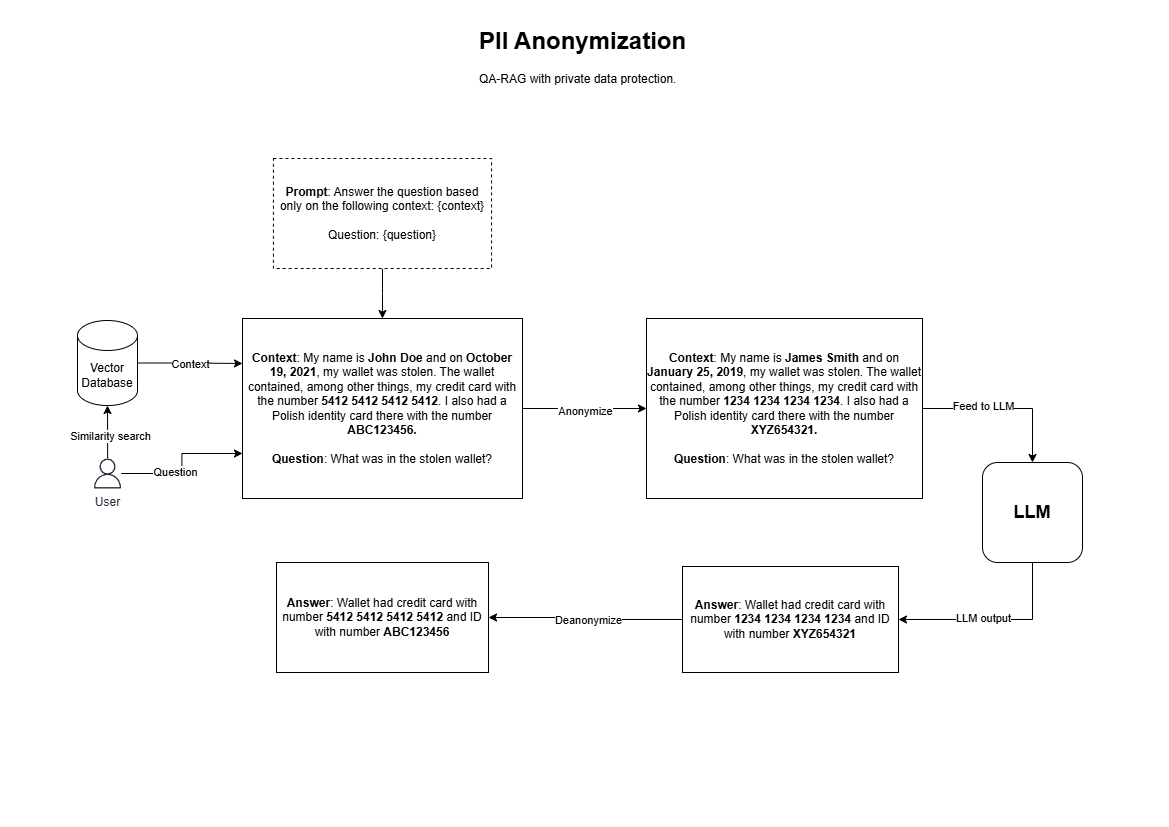

In [32]:
from IPython.display import Image
Image("./PII_Anonymization.png")

## References and materials

1. **LLMs: Data Privacy and Protection, PII Anonymisation** by Hands-on AI, Youtube.com.